In [19]:
import numpy as np
import pandas as pd
import pyagrum as gum
import pyagrum.lib.notebook as gnb
import pyagrum.lib.dynamicBN as gdyn

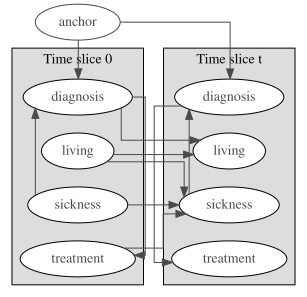

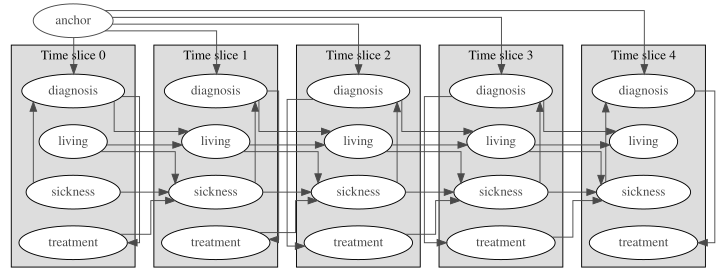

In [20]:
bn2 = gum.loadBN("elder_care_dbn/data/elder_twodbn.bif")
gdyn.showTimeSlices(bn2)

T = 5
dbn2 = gdyn.unroll2TBN(bn2, T)
gdyn.showTimeSlices(dbn2, size="10")

In [21]:
from cross_impact.model import build_network, UncertaintyFactor, CrossImpactNetwork
from cross_impact.pyagrum_import import marginals_and_joint_from_pyagrum
from cross_impact.pyagrum_export import graft_onto_pyagrum
from cross_impact.model import cross_impacts_from_joint

[0.67461952 0.2731386  0.00534759 0.04689428 0.        ]
[0.67731428 0.2729381  0.00490083 0.04403718 0.00080961]
[0.92269278 0.050158   0.01892739 0.00822183]
[0.92301218 0.05024713 0.01862483 0.00811586]


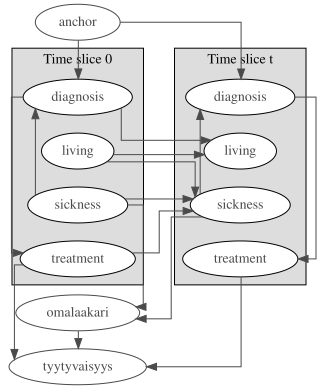

In [22]:
# extract from the learned BN
marginals, joint = marginals_and_joint_from_pyagrum(
    bn2, 
    ["sickness0", "sicknesst", "treatment0", "treatmentt",],
)

# Expert judgments
cross_impacts = {
    (0, 4): np.array([
        [1, 1],
        [1, 1],
        [1, 1], # should probably find some sort of balance between these
        [1, 1],
        [1, 1],
    ]),
    (1, 4): np.array([
        [1, 1],
        [1, 1],
        [1, 1],
        [1, 1],
        [1, 1],
    ]),
    (2, 5): np.array([
        [1,1,1],
        [1,1,1],
        [1,1,1],
        [1,1,1],
    ]),
    (3, 5):  np.array([
        [1,1,1],
        [1,1,1],
        [1,1,1],
        [1,1,1],
    ]),
    (4, 5): np.array([
        [1,0,-1], # no omalääkäri, satisfaction low
        [-1,0,1], # if omalääkäri, satisfaction high
    ]),
}

for marginal in marginals:
    print(marginal)

factors = [
    UncertaintyFactor("sickness0", 5, ()),
    UncertaintyFactor("sicknesst", 5, (0,)),
    UncertaintyFactor("treatment0", 4, ()),
    UncertaintyFactor("treatmentt", 4, (2,)),
    UncertaintyFactor("omalaakari", 2, (0, 1,)),
    UncertaintyFactor("tyytyvaisyys", 3, (2, 3, 4,)),
]
marginal_omalaakari = np.array([0.45, 0.55])
marginal_tyytyvaisyys = np.array([0.33, 0.33, 0.34])

# new bn
network = CrossImpactNetwork(
    factors=factors,
    marginals=[
        marginals[0], 
        marginals[1],
        marginals[2],
        marginals[3],
        marginal_omalaakari,
        marginal_tyytyvaisyys,
    ],
    cross_impacts=cross_impacts,
)

# attach new bn to old bn
built=build_network(network, mode="exact", initial_joint=joint)
merged=graft_onto_pyagrum(bn2, built, n_given=4)
gdyn.showTimeSlices(merged)

gnb.sideBySide(merged.cpt("omalaakari"), merged.cpt("tyytyvaisyys"))

# this cannot be expanded to a DBN it seems, we'll need to use "time 0" and "time t" nodes


[0.67461952 0.2731386  0.00534759 0.04689428 0.        ]
[0.67731428 0.2729381  0.00490083 0.04403718 0.00080961]
[0.92269278 0.050158   0.01892739 0.00822183]
[0.92301218 0.05024713 0.01862483 0.00811586]


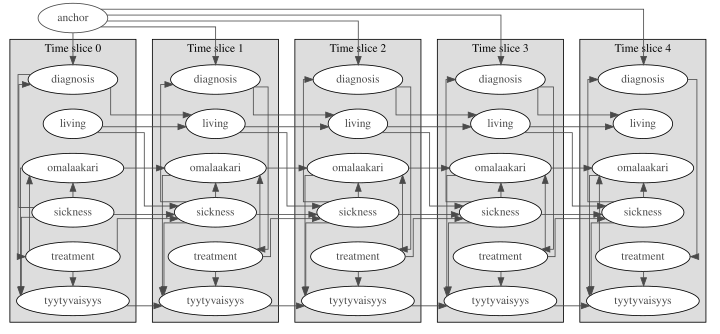

In [23]:
# extract from the learned BN
marginals, joint = marginals_and_joint_from_pyagrum(
    bn2, 
    ["sickness0", "sicknesst", "treatment0", "treatmentt",],
)

# Expert judgments
cross_impacts = {
    (0, 4): np.array([
        [1, 1],
        [1, 1],
        [1, 1], # should probably find some sort of balance between these
        [1, 1],
        [1, 1],
    ]),
    (1, 5): np.array([
        [1, 1],
        [1, 1],
        [1, 1],
        [1, 1],
        [1, 1],
    ]),
    (2, 4): np.array([
        [1,1],
        [1,1],
        [1,1],
        [1,1],
    ]),
    (3, 5):  np.array([
        [1,1],
        [1,1],
        [1,1],
        [1,1],
    ]),
    (4, 5): np.array([
        [1,0],
        [0,1], 
    ]),
    (0, 6): np.array([
        [1,1,1],
        [1,1,1],
        [1,1,1],
        [1,1,1],
        [1,1,1],
    ]),
    (2, 6): np.array([
        [1,1,1],
        [1,1,1],
        [1,1,1],
        [1,1,1],
    ]),
    (4, 6): np.array([
        [-1,0,1],
        [1,0,-1]
    ]),
    (1, 7): np.array([
        [1,1,1],
        [1,1,1],
        [1,1,1],
        [1,1,1],
        [1,1,1],
    ]),
    (3, 7): np.array([
        [1,1,1],
        [1,1,1],
        [1,1,1],
        [1,1,1],
    ]),
    (5, 7): np.array([
        [-1,0,1],
        [1,0,-1],
    ]),
    (6, 7): np.array([
        [1,1,1],
        [1,1,1],
        [1,1,1],
    ]),
}

for marginal in marginals:
    print(marginal)

factors = [
    UncertaintyFactor("sickness0", 5, ()),
    UncertaintyFactor("sicknesst", 5, (0,)),
    UncertaintyFactor("treatment0", 4, ()),
    UncertaintyFactor("treatmentt", 4, (2,)),
    UncertaintyFactor("omalaakari0", 2, (0, 2,)),
    UncertaintyFactor("omalaakarit", 2, (1, 3, 4,)),
    UncertaintyFactor("tyytyvaisyys0", 3, (0, 2, 4,)),
    UncertaintyFactor("tyytyvaisyyst", 3, (1, 3, 5, 6,)),
]
marginal_omalaakari0   = np.array([0.45, 0.55])
marginal_omalaakarit   = np.array([0.55, 0.45])
marginal_tyytyvaisyys0 = np.array([0.33, 0.33, 0.34])
marginal_tyytyvaisyyst = np.array([0.33, 0.33, 0.34])

# new bn
network = CrossImpactNetwork(
    factors=factors,
    marginals=[
        marginals[0], 
        marginals[1],
        marginals[2],
        marginals[3],
        marginal_omalaakari0,
        marginal_omalaakarit,
        marginal_tyytyvaisyys0,
        marginal_tyytyvaisyyst
    ],
    cross_impacts=cross_impacts,
)

# attach new bn to old bn
built=build_network(network, mode="exact", initial_joint=joint)
merged=graft_onto_pyagrum(bn2, built, n_given=4)

# Save merged to files
gum.saveBN(merged, "elder_care_dbn/data/ci_bn.bif")

T = 5
dmerged = gdyn.unroll2TBN(merged, T)
# gdyn.showTimeSlices(dmerged, size="10")

#gnb.sideBySide(dmerged.cpt("omalaakari666"), dmerged.cpt("omalaakari667"))
#gnb.sideBySide(dmerged.cpt("tyytyvaisyys666"), dmerged.cpt("tyytyvaisyys667"))

gdyn.showTimeSlices(dmerged, size="10")


In [24]:
from elder_care_dbn.cost_influence_diagram import expected_total_cost

T = 1000
total, per_timestep = expected_total_cost("elder_care_dbn/data/ci_bn.bif", T)
# NOTE: this version has "omalaakari" added, with daily costs etc.
print(f"average expected daily cost per timestep: {sum(per_timestep)/len(per_timestep)}")
print(f"expected total cost over {T} timesteps: {total}")

average expected daily cost per timestep: 10.203676925219936
expected total cost over 1000 timesteps: 10203.676925219936


In [40]:
from elder_care_dbn.stationary_policy import (
    build_mdp,
    value_iteration,
    evaluate_policy,
    DIAGNOSIS_LABELS,
    LIVING_LABELS,
    TREATMENT_LABELS,
    start_state_distribution,
    cost_and_health_tables,
    evaluate_deterministic_policy,
    solve_asf_policy
)

# Optimize policy
P, R, status_quo_policy = build_mdp("elder_care_dbn/data/ci_bn.bif")

gamma = 0.995
V_star, policy = value_iteration(P, R, gamma=gamma)
V_status_quo = evaluate_policy(P, R, status_quo_policy, gamma=gamma)

print(f"stationary optimal policy (gamma={gamma}):")
for di, d in enumerate(DIAGNOSIS_LABELS):
    chosen = {
        LIVING_LABELS[li]: TREATMENT_LABELS[policy[di, li]]
        for li in range(len(LIVING_LABELS))
    }
    print(f"  diagnosis={d:10s}: {chosen}")

print("\nvalue comparison (discounted, at living=INDEPENDENT):")
li = LIVING_LABELS.index("INDEPENDENT")
for di, d in enumerate(DIAGNOSIS_LABELS):
    print(
        f"  diagnosis={d:10s}: optimal={V_star[di, li]:9.2f}  status_quo={V_status_quo[di, li]:9.2f}"
    )

start = start_state_distribution("elder_care_dbn/data/ci_bn.bif")
print("\nexpected discounted value from the true t=0 start distribution:")
print(f"  optimal:    {(start * V_star).sum():.2f}")
print(f"  status quo: {(start * V_status_quo).sum():.2f}")

print("\nmulti-objective (ASF) example, treating cost and health penalty as separate objectives:")
cost_table, health_table = cost_and_health_tables()
_, cost_opt_policy = value_iteration(P, -cost_table, gamma=gamma)
_, health_opt_policy = value_iteration(P, -health_table, gamma=gamma)
ideal_cost = (start * evaluate_deterministic_policy(P, cost_table, cost_opt_policy, gamma)).sum()
ideal_health = (start * evaluate_deterministic_policy(P, health_table, health_opt_policy, gamma)).sum()
# illustrative reference point: aim for 50% above each objective's own
# best-case ideal (an aspiration a bit more ambitious than the combined
# weighted-sum optimum, but not the unreachable ideal point itself)
reference_point = (ideal_cost * 1.5, ideal_health * 1.5)

asf_policy, asf_value, ideal, nadir = solve_asf_policy(P, cost_table, health_table, reference_point, start, gamma=gamma)
achieved_cost = (start * evaluate_deterministic_policy(P, cost_table, asf_policy, gamma)).sum()
achieved_health = (start * evaluate_deterministic_policy(P, health_table, asf_policy, gamma)).sum()
print(f"  reference point: cost~{reference_point[0]:.1f}, health~{reference_point[1]:.1f}")
print(f"  ideal (per objective, isolated): cost={ideal[0]:.1f}, health={ideal[1]:.1f}")
print(f"  nadir (cross-evaluated worst case): cost={nadir[0]:.1f}, health={nadir[1]:.1f}")
print(f"  achieved: cost={achieved_cost:.1f}, health={achieved_health:.1f} (ASF value={asf_value:.4f})")
for di, d in enumerate(DIAGNOSIS_LABELS):
    chosen = {LIVING_LABELS[li]: TREATMENT_LABELS[asf_policy[di, li]] for li in range(len(LIVING_LABELS))}
    print(f"  diagnosis={d:10s}: {chosen}")

stationary optimal policy (gamma=0.995):
  diagnosis=NONE      : {'INDEPENDENT': 'NONE', 'FAMILY_CARE': 'NONE', 'HOME_CARE': 'NONE', 'HEALTH_CENTRE': 'NONE'}
  diagnosis=MILD      : {'INDEPENDENT': 'NONE', 'FAMILY_CARE': 'NONE', 'HOME_CARE': 'NONE', 'HEALTH_CENTRE': 'NONE'}
  diagnosis=MEDIUM    : {'INDEPENDENT': 'NONE', 'FAMILY_CARE': 'NONE', 'HOME_CARE': 'HEALTH_CENTRE', 'HEALTH_CENTRE': 'NONE'}
  diagnosis=DIFFICULT : {'INDEPENDENT': 'HEALTH_CENTRE', 'FAMILY_CARE': 'ED', 'HOME_CARE': 'HEALTH_CENTRE', 'HEALTH_CENTRE': 'NONE'}
  diagnosis=DEAD      : {'INDEPENDENT': 'NONE', 'FAMILY_CARE': 'NONE', 'HOME_CARE': 'NONE', 'HEALTH_CENTRE': 'NONE'}

value comparison (discounted, at living=INDEPENDENT):
  diagnosis=NONE      : optimal= -3818.26  status_quo= -5535.94
  diagnosis=MILD      : optimal= -4290.22  status_quo= -6159.41
  diagnosis=MEDIUM    : optimal= -4774.74  status_quo= -7252.46
  diagnosis=DIFFICULT : optimal= -5296.31  status_quo=-11995.82
  diagnosis=DEAD      : optimal=-31761